In [1]:
import numpy as np
import pandas as pd
import json
import yaml
from matplotlib import pyplot as plt
%matplotlib widget
from matplotlib.backend_bases import MouseButton
from scipy.interpolate import CubicSpline

/tmp/ipykernel_2534871/2973866984.py:2: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


## Social Nav

### Agents Trajectory

In [2]:
agent_1 = ([-4.994387096774194,
  -4.459161290322581,
  -3.95541935483871,
  -3.420193548387097,
  -2.9164516129032263,
  -2.6173548387096783,
  -1.9719354838709684,
  -1.4209677419354847,
  -1.0746451612903236,
  -0.5709032258064521,
  -0.3190322580645173],
 [3.3289677419354806,
  3.3447096774193508,
  3.2345161290322526,
  3.360451612903221,
  3.3919354838709648,
  3.2817419354838666,
  3.3132258064516105,
  3.376193548387091,
  3.3447096774193508,
  2.9983870967741897,
  2.9511612903225757])

agent_2 = ([-2.9951612903225815,
  -2.6330967741935485,
  -2.239548387096775,
  -1.7672903225806458,
  -1.4209677419354847,
  -1.169096774193549,
  -0.870000000000001,
  -0.5709032258064521,
  -0.19309677419354898,
  0.10599999999999898,
  0.37361290322580576,
  0.5782580645161284],
 [4.2419999999999956,
  4.383677419354834,
  4.352193548387094,
  4.446645161290318,
  4.556838709677416,
  4.556838709677416,
  4.446645161290318,
  4.415161290322574,
  4.415161290322574,
  4.32070967741935,
  4.383677419354834,
  4.430903225806448])

agent_3 = ([0.5310322580645161,
  0.468064516129032,
  0.6097419354838705,
  0.5625161290322565,
  0.6097419354838705,
  0.5310322580645161,
  0.6254838709677406,
  0.5939999999999985,
  0.6727096774193546,
  0.6727096774193546,
  0.6254838709677406,
  0.6097419354838705,
  0.6727096774193546,
  0.7986451612903211],
 [-3.4872903225806464,
  -3.1094838709677433,
  -2.5900000000000016,
  -2.05477419354839,
  -1.5352903225806482,
  -0.9213548387096804,
  -0.5750322580645193,
  0.03890322580644856,
  0.4009677419354798,
  1.140838709677416,
  1.5501290322580612,
  2.0853548387096748,
  2.5890967741935444,
  2.9826451612903195])

agent_4 = ([-4.9314193548387095,
  -4.632322580645162,
  -4.333225806451614,
  -4.065612903225807,
  -3.7980000000000005,
  -3.546129032258065,
  -3.2155483870967743,
  -2.884967741935484,
  -2.459935483870968,
  -2.239548387096775,
  -1.9404516129032263,
  -1.7043225806451616,
  -1.5626451612903232],
 [-0.43335483870968083,
  -0.43335483870968083,
  -0.3074193548387125,
  -0.4176129032258089,
  -0.48058064516129306,
  -0.48058064516129306,
  -0.3703870967741967,
  -0.43335483870968083,
  -0.496322580645165,
  -0.3703870967741967,
  -0.32316129032258445,
  -0.32316129032258445,
  -0.32316129032258445])

agent_5 = ([-4.994387096774194,
  -4.868451612903226,
  -4.632322580645162,
  -4.474903225806452,
  -4.238774193548387,
  -3.7350322580645168,
  -3.483161290322581,
  -3.152580645161291,
  -2.853483870967742,
  -2.538645161290323,
  -2.192322580645162,
  -1.9404516129032263,
  -1.5941290322580652,
  -1.483935483870968],
 [-1.1732258064516152,
  -1.1889677419354872,
  -1.3463870967741958,
  -1.4565806451612922,
  -1.4565806451612922,
  -1.2991612903225835,
  -1.2991612903225835,
  -1.40935483870968,
  -1.4565806451612922,
  -1.3621290322580677,
  -1.2519354838709713,
  -1.2204516129032292,
  -1.1732258064516152,
  -1.3621290322580677])

agent_6 = ([-1.861741935483872,
  -2.0191612903225815,
  -2.082129032258065,
  -2.208064516129033,
  -2.6330967741935485,
  -2.7432903225806458,
  -3.121096774193549,
  -3.6405806451612905,
  -3.7822580645161294,
  -4.065612903225807,
  -4.3017419354838715,
  -4.2860000000000005,
  -4.569354838709678,
  -4.868451612903226],
 [-2.5427741935483894,
  -2.3223870967741966,
  -1.8501290322580672,
  -1.5667741935483903,
  -1.1889677419354872,
  -0.811161290322584,
  -0.6694838709677455,
  -0.5592903225806474,
  -0.19722580645161614,
  -0.03980645161290575,
  0.3694838709677395,
  0.6843225806451567,
  0.8732258064516092,
  0.9834193548387073])

agent_7 = ([3.5062580645161274,
  3.8683225806451604,
  4.450774193548386,
  4.875806451612902,
  4.985999999999998,
  4.954516129032256,
  4.560967741935483,
  4.2146451612903215,
  3.8840645161290306,
  3.5849677419354835],
 [3.4391612903225752,
  3.376193548387091,
  3.3447096774193508,
  3.061354838709674,
  2.5261290322580603,
  2.400193548387092,
  1.9909032258064467,
  1.9436774193548363,
  1.6918064516128997,
  1.6603225806451594])

agent_8 = ([3.396064516129031,
  3.081225806451612,
  2.656193548387095,
  2.8136129032258053,
  2.766387096774193,
  3.0025161290322577,
  3.2701290322580627,
  3.348838709677419,
  3.616451612903224],
 [0.9834193548387073,
  0.8732258064516092,
  0.6213548387096726,
  0.2750322580645115,
  -0.07129032258064782,
  -0.24445161290322837,
  -0.5278064516129071,
  -0.6537419354838736,
  -0.5435483870967772])

agent_9 = ([2.1681935483870953,
  2.0107741935483867,
  2.042258064516129,
  1.9635483870967727,
  2.042258064516129,
  1.9792903225806446,
  2.0107741935483867,
  1.9478064516129026,
  2.089483870967741,
  1.9950322580645148,
  2.2311612903225795,
  2.467290322580644],
 [-4.258645161290325,
  -3.9123225806451636,
  -3.5660000000000025,
  -3.078000000000003,
  -2.6057419354838736,
  -2.133483870967744,
  -1.6927096774193569,
  -1.2676774193548415,
  -0.9528387096774225,
  -0.6380000000000035,
  -0.4176129032258089,
  -0.1814838709677442])

agent_10 = ([ 3.755],
  [ -3.0])

agent_11 = ([5.033225806451612,
  4.781354838709675,
  4.560967741935483,
  4.2146451612903215,
  3.8998064516129025,
  3.4905161290322573,
  3.301612903225805],
 [-1.9445806451612935,
  -1.755677419354841,
  -1.755677419354841,
  -1.8658709677419374,
  -1.8501290322580672,
  -1.724193548387099,
  -1.9288387096774215])

agents = [agent_1, agent_2, agent_3, agent_4, agent_5, agent_6, agent_7, agent_8, agent_9, agent_10, agent_11]
    

### Plot

2 0
3 1
4 2
8 3


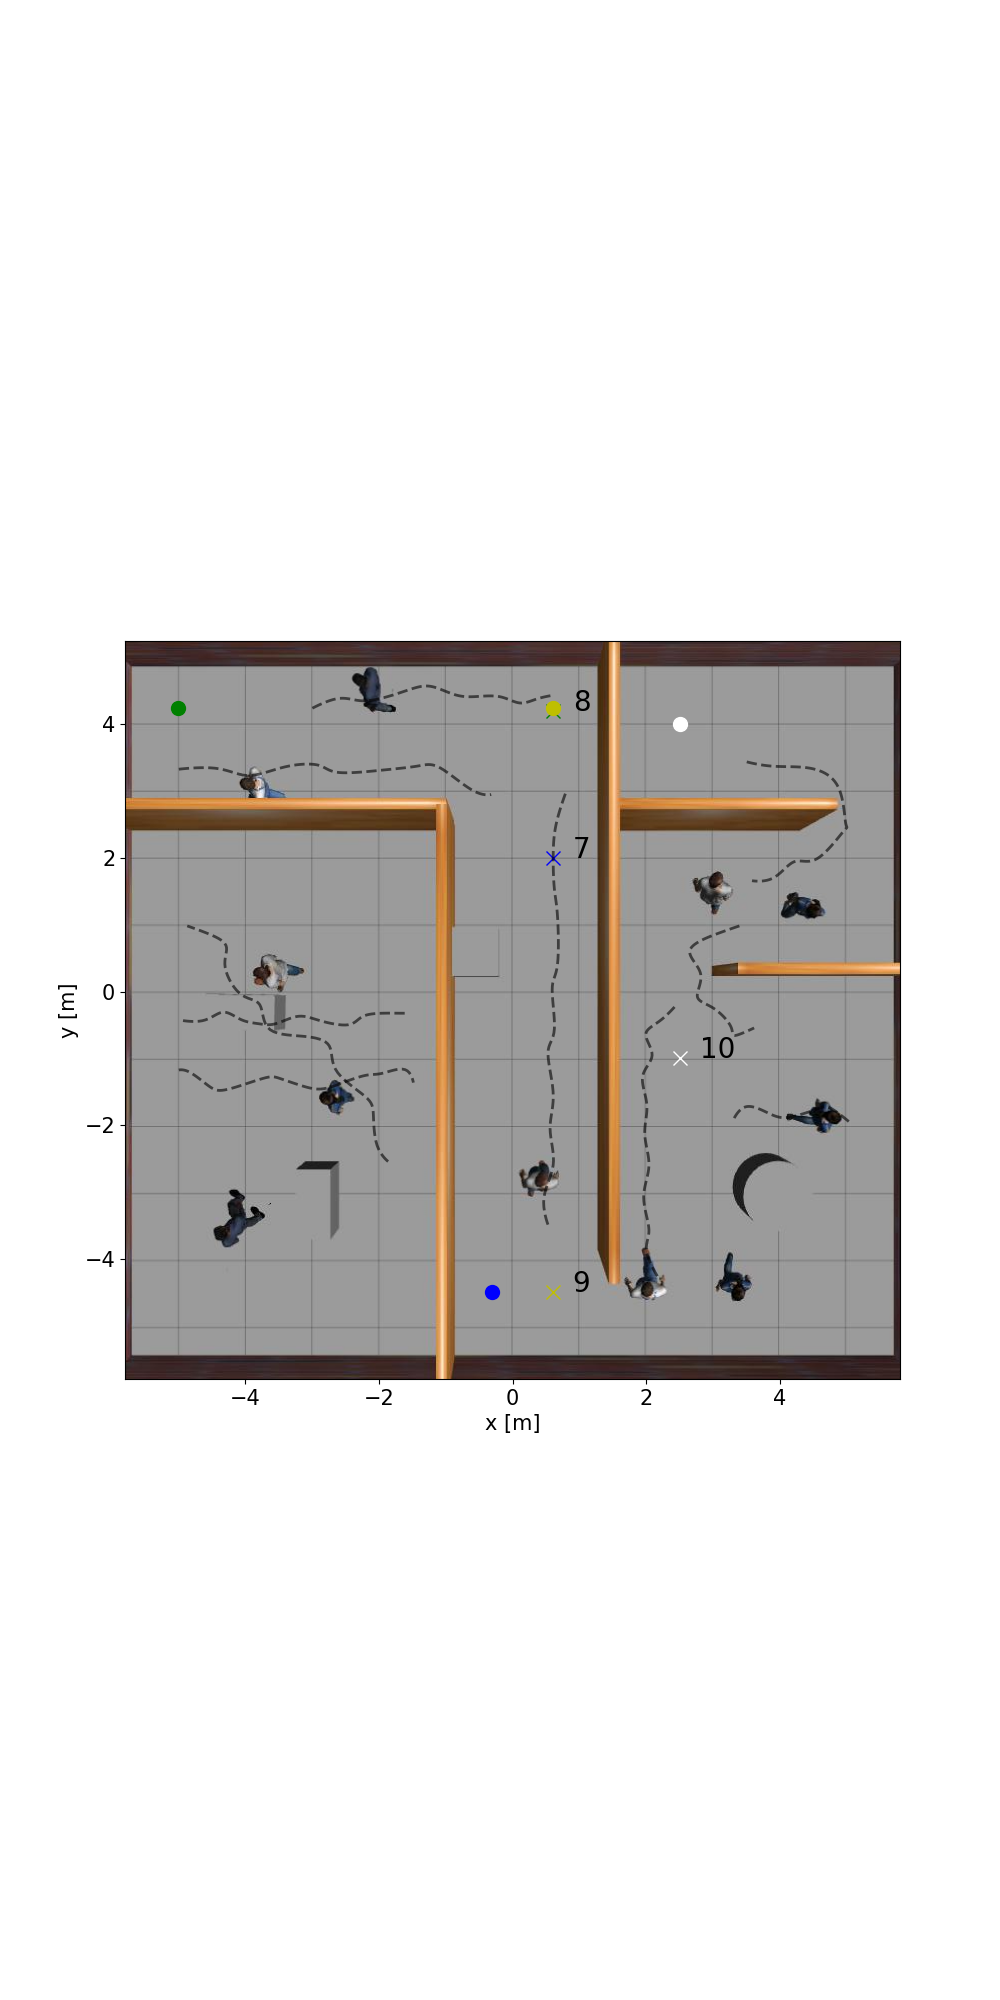

done


In [3]:
# Load the data (JSON file)
x_capture =[]
y_capture = []

json_file = '/home/user/applr_ws/src/APPLR_social_nav/applr_social_nav/goals_and_poses/social_env_test.json'
json_file2 = '/home/user/applr_ws/src/APPLR_social_nav/applr_social_nav/goals_and_poses/social_env7_test.json'
world_image = '/home/user/.gazebo/pictures/default_gzclient_camera(1)-2024-03-15T04_32_04.918403.jpg'

def on_click(event):
    if event.button is MouseButton.LEFT:
        print('disconnecting callback')
        plt.disconnect(binding_id)
    elif event.button is MouseButton.RIGHT and event.inaxes:
        x_captured = event.xdata
        y_captured = event.ydata
        x_capture.append(x_captured)
        y_capture.append(y_captured)
        plt.plot(x_captured, y_captured, 'ro')

def on_close(event):
    print('closing figure')
    print(x_capture, y_capture)
    plt.close(fig)

x = json.load(open(json_file))

goals = pd.DataFrame(x['goals'], columns=['x', 'y'])
initial_poses = pd.DataFrame(x['poses'], columns=['x', 'y', 'theta'])

ax, fig = plt.subplots(1, 1, figsize=(10,20))
# plot the world image
img = plt.imread(world_image)
plt.xlabel('x [m]', fontsize=15)
plt.ylabel('y [m]', fontsize=15)
plt.xticks(fontsize=15)
plt.yticks(fontsize=15)
#crop the image
img = img[55:825, 470:1200]
img = np.rot90(img, k=3)
# rotate the image -90 degrees
plt.imshow(img, extent=[-5.8, 5.8,-5.8, 5.25])


# plot the goals and initial poses
colors = ['r', 'b', 'g', 'y', 'c', 'm', 'k', 'w', 'orange', 'purple']
# episodes = [2,3,4,5,7,9]
episodes =[2,3,4,8]
for j,i in enumerate(episodes):
    print(i,j)
    plt.plot(goals['x'][i-1], goals['y'][i-1], colors[i-1], marker='x', markersize=10)
    plt.plot(initial_poses['x'][i-1], initial_poses['y'][i-1], colors[i-1], marker='o', markersize=10)
# color legend with the number of the goal
for j,i in enumerate(episodes):
    # if(i == 3):
    #     plt.text(goals['x'][i-1] + 0.3, goals['y'][i-1], f'{i+1} = {i+2}', fontsize=12, color='black')
    # elif(i == 4):
    #     # plt.text(goals['x'][i]- 0.3, goals['y'][i] - 0.3,str(i+1), fontsize=12, color='black')
    #     pass
    # else:
        # plt.text(goals['x'][i]+ 0.3, goals['y'][i] , str(i+1), fontsize=12, color='black')
    plt.text(goals['x'][i-1] + 0.3, goals['y'][i-1], str(j+1+6), fontsize=20, color='black')

for i in range(len(agents)):
    # interpolate the trajectory with a spline
    if i == 9:
        continue
    x = np.array(agents[i][0])
    y = np.array(agents[i][1])
    t = np.arange(len(x))
    t_new = np.linspace(0, len(x)-1, 100)
    spl = CubicSpline(t, np.c_[x, y], bc_type='clamped')
    x_new, y_new = spl(t_new).T
    plt.plot(x_new, y_new, '--',alpha=0.6, linewidth=2, color='black')
    
binding_id = plt.connect('close_event', on_close)
plt.connect('button_press_event', on_click)
plt.show()
print('done')


plt.savefig('social_env_test.png', dpi=300, bbox_inches='tight')

### Table goals and poses

In [4]:
# Generate table for the goals and initial poses
goals_and_poses = goals.join(initial_poses, lsuffix='_g', rsuffix='_i')
goals_and_poses.index = range(1, len(goals)+1)
goals_and_poses.rename_axis('Episode', inplace=True)
goals_and_poses.rename(columns={'theta': 'theta_i'}, inplace=True)
goals_and_poses.columns = pd.MultiIndex.from_tuples([('Goal', 'x'), ('Goal', 'y'), ('Initial Pose', 'x'), ('Initial Pose', 'y'), ('Initial Pose', 'theta')])
goals_and_poses
selected_goals_and_poses = goals_and_poses.loc[episodes]
selected_goals_and_poses

Goal      Initial Pose            
           x    y            x     y theta
Episode                                   
2        0.6  2.0         -0.3 -4.50  1.57
3        0.6  4.2         -5.0  4.25  0.00
4        0.6 -4.5          0.6  4.25 -1.57
8        2.5 -1.0          2.5  4.00  0.00

## Social env

### Agent Trajectory

In [5]:
agent_1 = ([3.6540000000000004,
  3.850451612903226,
  4.204064516129032,
  4.505290322580645,
  4.858903225806452,
  5.094645161290323,
  5.461354838709678,
  5.828064516129032,
  6.155483870967743,
  6.5352903225806465,
  6.902000000000001,
  7.242516129032259,
  7.63541935483871,
  7.844967741935484,
  8.211677419354839,
  8.395032258064516,
  8.539096774193549,
  8.656967741935485],
 [8.485516129032263,
  8.40693548387097,
  8.367645161290326,
  8.42003225806452,
  8.43312903225807,
  8.380741935483876,
  8.42003225806452,
  8.40693548387097,
  8.302161290322584,
  8.354548387096777,
  8.459322580645164,
  8.341451612903228,
  8.328354838709682,
  8.393838709677421,
  8.380741935483876,
  8.275967741935489,
  8.26287096774194,
  8.26287096774194])

agent_2 = ([1.5061290322580647,
  1.5454193548387098,
  1.6109032258064517,
  1.624,
  1.7156774193548388,
  1.7549677419354839,
  1.7811612903225806,
  1.9907096774193547,
  2.1740645161290324,
  2.200258064516129,
  2.1740645161290324,
  2.1478709677419356,
  2.121677419354839,
  2.095483870967742,
  1.9514193548387095,
  1.9121290322580644,
  1.9121290322580644,
  1.8728387096774193],
 [7.5687419354838745,
  7.228225806451615,
  6.887709677419359,
  6.337645161290325,
  5.944741935483872,
  5.617322580645165,
  5.172032258064519,
  4.9231935483871005,
  4.373129032258067,
  4.045709677419357,
  3.862354838709681,
  3.364677419354841,
  3.2337096774193554,
  2.8277096774193566,
  2.421709677419358,
  2.0157096774193572,
  1.7406774193548404,
  1.243000000000002])

agent_3 = ([1.7156774193548388,
  1.7287741935483871,
  1.689483870967742,
  1.689483870967742,
  1.7025806451612904,
  1.6370967741935485,
  1.6632903225806452,
  1.5061290322580647,
  1.4668387096774196,
  1.4668387096774196,
  1.5585161290322582,
  1.5585161290322582,
  1.6109032258064517],
 [-0.4071935483870952,
  -0.7215161290322563,
  -1.0096451612903206,
  -1.2453870967741913,
  -1.5989999999999984,
  -1.9395161290322562,
  -2.24074193548387,
  -2.5419677419354834,
  -2.843193548387095,
  -3.1444193548387087,
  -3.6159032258064503,
  -3.917129032258064,
  -4.218354838709676])

agent_4 = ([3.5230322580645166,
  3.5885161290322585,
  3.640903225806452,
  3.640903225806452,
  3.680193548387097,
  3.6147096774193552,
  3.6540000000000004,
  3.6147096774193552,
  3.7194838709677422,
  3.7587741935483874,
  3.889741935483871,
  3.98141935483871,
  3.915935483870968,
  3.9028387096774195,
  3.889741935483871,
  3.955225806451613,
  3.9683225806451614,
  3.955225806451613,
  3.8373548387096776,
  3.811161290322581,
  3.7718709677419358,
  3.6932903225806455,
  3.6540000000000004,
  3.601612903225807],
 [-3.327774193548386,
  -3.052741935483869,
  -2.777709677419354,
  -2.48958064516129,
  -2.1621612903225795,
  -1.6382903225806444,
  -0.8655806451612893,
  -0.09287096774193415,
  0.41790322580645345,
  0.719129032258067,
  1.2691935483870989,
  0.6405483870967768,
  0.07738709677419564,
  -0.5119677419354822,
  -1.2453870967741913,
  -1.9919032258064497,
  -2.5812580645161276,
  -3.0658387096774184,
  -3.4849354838709665,
  -3.8385483870967736,
  -4.139774193548385,
  -4.6374516129032255,
  -5.056548387096774,
  -5.475645161290322])

agent_5 = ([8.552193548387098,
  8.316451612903226,
  7.910451612903227,
  7.648516129032259,
  7.386580645161292,
  7.046064516129032,
  6.692451612903227,
  6.26025806451613,
  5.880451612903226,
  5.579225806451612,
  5.1732258064516135,
  4.819612903225806,
  4.204064516129032,
  3.9683225806451614,
  3.8242580645161293],
 [4.805322580645164,
  5.027967741935488,
  5.132741935483875,
  5.15893548387097,
  5.14583870967742,
  5.106548387096776,
  4.975580645161294,
  4.897000000000002,
  4.752935483870971,
  4.6088709677419395,
  4.477903225806454,
  4.412419354838711,
  4.242161290322581,
  4.045709677419357,
  3.7968709677419383])

agent_6 = ([6.58767741935484, 6.58767741935484, 6.58767741935484],
 [3.5218387096774215, 3.5218387096774215, 3.4956451612903265])

agent_7 = ([8.133096774193548,
  8.172387096774195,
  8.04141935483871,
  8.237870967741936,
  8.198580645161291,
  8.093806451612904,
  7.9628387096774205,
  7.871161290322581,
  7.700903225806453,
  7.163935483870969,
  6.823419354838711,
  6.522193548387097,
  6.26025806451613,
  6.286451612903226,
  6.456709677419356,
  6.574580645161291,
  6.757935483870968,
  6.9150967741935485,
  7.0198709677419355,
  7.150838709677419,
  7.425870967741936,
  7.766387096774194,
  8.080709677419355],
 [-5.619709677419354,
  -5.81616129032258,
  -6.012612903225806,
  -6.366225806451612,
  -6.719838709677419,
  -6.968677419354838,
  -7.348483870967741,
  -7.675903225806452,
  -7.754483870967742,
  -7.754483870967742,
  -7.754483870967742,
  -7.754483870967742,
  -7.754483870967742,
  -7.4925483870967735,
  -7.165129032258064,
  -6.95558064516129,
  -6.746032258064516,
  -6.575774193548386,
  -6.2745483870967735,
  -6.051903225806451,
  -5.881645161290322,
  -5.711387096774192,
  -5.606612903225805])

agent_8 = ([8.591483870967743,
  8.237870967741936,
  7.871161290322581,
  7.583032258064517,
  7.190129032258065,
  6.784129032258065,
  6.456709677419356,
  5.945935483870969,
  5.4875483870967745,
  5.016064516129033,
  4.636258064516129,
  4.204064516129032],
 [-3.563516129032257,
  -3.5504193548387093,
  -3.563516129032257,
  -3.563516129032257,
  -3.5897096774193535,
  -3.6159032258064503,
  -3.576612903225806,
  -3.602806451612903,
  -3.681387096774193,
  -3.7206774193548373,
  -3.7337741935483866,
  -3.7992580645161276])

agent_9 = ([5.775677419354839,
  5.959032258064516,
  6.194774193548387,
  6.391225806451613,
  6.574580645161291,
  6.771032258064517,
  7.032967741935485,
  6.9543870967741945,
  6.653161290322581,
  6.273354838709677,
  5.932838709677419,
  5.566129032258065,
  5.435161290322581],
 [-0.2369354838709654,
  -0.2893225806451589,
  -0.4595806451612887,
  -0.6167419354838692,
  -0.786999999999999,
  -1.0751290322580633,
  -1.5204193548387082,
  -1.7037741935483854,
  -1.860935483870966,
  -1.9919032258064497,
  -2.1490645161290303,
  -2.306225806451611,
  -2.3324193548387075])

agent_10 = ([2.4752903225806455, 2.6062580645161293],
 [-6.209064516129032, -6.248354838709677])

agent_11 = ([
  6.679354838709678,
  6.561483870967743,
  6.443612903225807,
  6.378129032258066],
 [-6.012612903225806,
  -5.8554516129032255,
  -5.632806451612902,
  -5.41016129032258])

agent_12 = ([0.6286451612903226, 0.6286451612903226],
 [3.4039677419354852, 3.4039677419354852])

agent_13 =  ([1.3489677419354837,
  1.584709677419355,
  1.7418709677419355,
  1.8728387096774193,
  2.095483870967742,
  2.3967096774193553,
  2.671741935483871,
  2.9860645161290322,
  3.3003870967741933,
  3.706387096774194,
  4.0207096774193545,
  4.1647741935483875,
  4.086193548387097,
  3.9421290322580647,
  3.850451612903226,
  3.8242580645161293,
  3.784967741935484],
 [-6.025709677419354,
  -6.195967741935483,
  -6.353129032258064,
  -6.470999999999999,
  -6.6543548387096765,
  -6.824612903225806,
  -7.03416129032258,
  -7.256806451612903,
  -7.479451612903225,
  -7.819967741935484,
  -8.055709677419355,
  -7.964032258064516,
  -7.662806451612902,
  -7.348483870967741,
  -7.073451612903225,
  -6.680548387096773,
  -6.326935483870967])

agent_14 = ([7.583032258064517,
  7.47825806451613,
  7.465161290322582,
  7.438967741935485,
  7.425870967741936,
  7.465161290322582,
  7.412774193548389,
  7.412774193548389,
  7.412774193548389],
 [0.37861290322580743,
  0.2607419354838729,
  0.011903225806452866,
  -0.3024193548387082,
  -0.577451612903225,
  -0.8262903225806433,
  -1.0882258064516108,
  -1.3239677419354816,
  -1.481129032258064])

agents = [agent_1, agent_2, agent_3, agent_4, agent_5, agent_6, agent_7, agent_8, agent_9, agent_10, agent_11, agent_12, agent_13, agent_14]



## Plot

(881, 1636, 3)


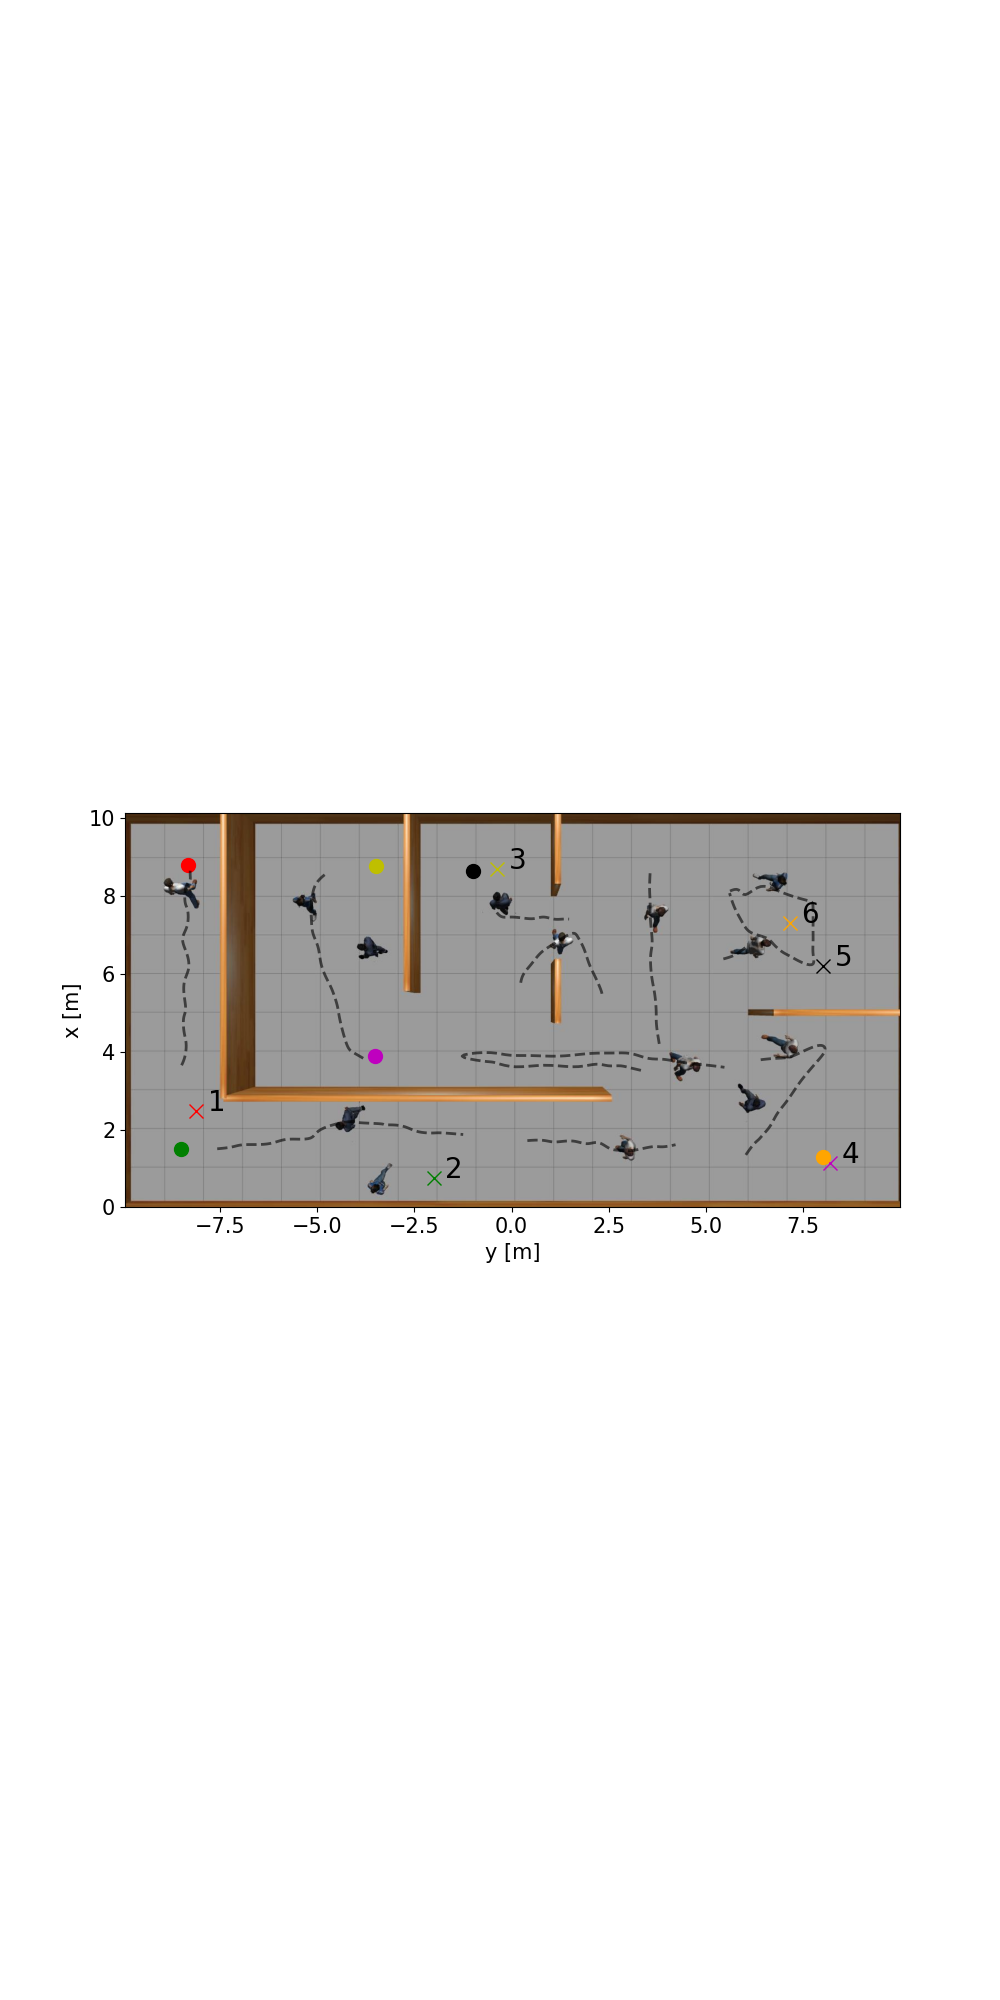

In [6]:
# load the json file
x_capture =[]
y_capture = []

json_file = '/home/user/applr_ws/src/APPLR_social_nav/applr_social_nav/goals_and_poses/social_nav_test.json'
x = json.load(open(json_file))
world_image = '/home/user/.gazebo/pictures/default_gzclient_camera(1)-2024-03-13T10_17_56.637851.jpg'

fig, ax = plt.subplots(1, 1, figsize=(10,20))
plt.xlabel('y [m]', fontsize=15)
plt.ylabel('x [m]', fontsize=15)
plt.xticks(fontsize=15)
plt.yticks(fontsize=15)
# plot the world image
img = plt.imread(world_image)
print(img.shape)
#crop the image
img = img[80:800,110:1515]
# img = np.rot90(img)
# rotate the image -90 degrees
# plt.imshow(img, extent=[-0.0, 10.15,-9.94, 9.99])
plt.imshow(img, extent=[-9.94, 9.99,-0.0, 10.15])

goals = pd.DataFrame(x['goals'], columns=['x', 'y'])
initial_poses = pd.DataFrame(x['poses'], columns=['x', 'y', 'theta'])

# plot the goals and initial poses
colors = ['r', 'b', 'g', 'y', 'c', 'm', 'k', 'w', 'orange', 'purple']
episodes = [1, 3, 4, 6, 7, 9]
for j,i in enumerate(episodes):
# for i in range(1,len(goals)+1):
    plt.plot(-goals['y'][i-1], goals['x'][i-1], colors[i-1], marker='x', markersize=10)
    plt.plot(-initial_poses['y'][i-1], initial_poses['x'][i-1], colors[i-1], marker='o', markersize=10)
    plt.text(-goals['y'][i-1]+ 0.3, goals['x'][i-1] , str(j+1), fontsize=20, color='black')

for i in range(len(agents)):
    # interpolate the trajectory with a spline
    if i == 9 or i == 11:
        continue
    x = np.array(agents[i][1])
    y = np.array(agents[i][0])
    t = np.arange(len(x))
    t_new = np.linspace(0, len(x)-1, 100)
    spl = CubicSpline(t, np.c_[x, y], bc_type='clamped')
    x_new, y_new = spl(t_new).T
    plt.plot(-x_new, y_new, '--',alpha=0.6, linewidth=2, color='black')

# binding_id = plt.connect('close_event', on_close)
# plt.connect('button_press_event', on_click)
# plt.show()
# print('done')
plt.show()
plt.savefig('social_nav_test.png', dpi=300, bbox_inches='tight')

In [7]:
# Generate table for the goals and initial poses
goals_and_poses2 = goals.join(initial_poses, lsuffix='_g', rsuffix='_i')
goals_and_poses2.index = range(1, len(goals)+1)
goals_and_poses2.rename_axis('Episode', inplace=True)
goals_and_poses2.rename(columns={'theta': 'theta_i'}, inplace=True)
goals_and_poses2.columns = pd.MultiIndex.from_tuples([('Goal', 'x'), ('Goal', 'y'), ('Initial Pose', 'x'), ('Initial Pose', 'y'), ('Initial Pose', 'theta')])
goals_and_poses2
selected_goals_and_poses2 = goals_and_poses2.loc[episodes]

selected_goals_and_poses2

Goal        Initial Pose              
            x      y            x      y  theta
Episode                                        
1        2.49  8.110         8.80  8.320 -3.000
3        0.76  2.000         1.50  8.510 -1.571
4        8.70  0.369         8.77  3.479 -3.139
6        1.15 -8.200         3.90  3.500 -1.576
7        6.20 -8.020         8.65  1.000 -2.610
9        7.30 -7.150         1.29 -8.000  0.100

In [8]:
total_goals_and_poses = pd.concat([selected_goals_and_poses2, selected_goals_and_poses])
total_goals_and_poses.episode = [str(i) for i in range(1, len(total_goals_and_poses)+1)]
total_goals_and_poses


/tmp/ipykernel_2534871/618798221.py:2: UserWarning: Pandas doesn't allow columns to be created via a new attribute name - see https://pandas.pydata.org/pandas-docs/stable/indexing.html#attribute-access
  total_goals_and_poses.episode = [str(i) for i in range(1, len(total_goals_and_poses)+1)]


Goal        Initial Pose              
            x      y            x      y  theta
Episode                                        
1        2.49  8.110         8.80  8.320 -3.000
3        0.76  2.000         1.50  8.510 -1.571
4        8.70  0.369         8.77  3.479 -3.139
6        1.15 -8.200         3.90  3.500 -1.576
7        6.20 -8.020         8.65  1.000 -2.610
9        7.30 -7.150         1.29 -8.000  0.100
2        0.60  2.000        -0.30 -4.500  1.570
3        0.60  4.200        -5.00  4.250  0.000
4        0.60 -4.500         0.60  4.250 -1.570
8        2.50 -1.000         2.50  4.000  0.000